# Material Characterization — Data Processing

Clean driver for the two studies delivered **2026-06-29**. All logic lives in the
[`utils/`](../utils) package; this notebook just orchestrates and displays.

| Study | Raw workbook | Outputs |
|---|---|---|
| **Tensile** (PP/PAL) | `Trial Data Analysis.xlsx` | stress–strain curves, modulus / UTS / toughness |
| **Rheology** (recycled HDPE) | `recycled HDPE-PAL-viscosity.xlsx` | viscosity flow curves, power-law fit |
| **DoE** | — | optimized Latin-hypercube design to hand off |

Everything writes into `processed_data/` and `doe/`; figures into `processed_data/figures/`.

In [1]:
import sys
from pathlib import Path

# Make the project root importable whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "utils").exists() and (ROOT.parent / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import config, io, tensile, rheology, doe, plots

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

p = config.paths(ROOT)
config.ensure_dirs(p)
TENSILE_XLSX, VISCOSITY_XLSX = io.extract_raw(p.raw)
print("project root :", p.root)
print("tensile      :", TENSILE_XLSX.name)
print("rheology     :", VISCOSITY_XLSX.name)

project root : /data/zhq7531/IDEAL/UIC_NU_new/multi_task
tensile      : Trial Data Analysis.xlsx
rheology     : recycled HDPE-PAL-viscosity.xlsx


---
## Part 1 — Tensile study

### 1.1 Configuration reference

In [2]:
config_meta = tensile.load_config_reference(TENSILE_XLSX)
config_meta

,config,pp_pct,pal_pct,extr_temp_C
0,10,50.0,50.0,180.0
1,13,75.0,25.0,180.0
2,20,100.0,0.0,180.0
3,14,75.0,25.0,200.0
4,16,100.0,0.0,200.0
5,12,50.0,50.0,200.0
6,15,75.0,25.0,220.0
7,9.5,50.0,50.0,220.0
8,18,100.0,0.0,220.0
9,11,50.0,50.0,240.0


### 1.2 Parse specimens → summary
Per-specimen tidy curves are written to `tensile/curves/`; scalar metrics
(modulus, UTS, toughness, strain-at-break) collected into one table.

In [3]:
curves, _raw = tensile.load_tensile(TENSILE_XLSX, p.tensile_curves)
tensile_summary = tensile.build_summary(_raw, config_meta)
tensile_summary.to_csv(p.tensile / "tensile_summary.csv", index=False)
print(f"parsed {len(curves)} specimens across {tensile_summary['config'].nunique()} configurations")
tensile_summary.head()

parsed 38 specimens across 12 configurations


,config,replicate,pp_pct,pal_pct,extr_temp_C,young_modulus_MPa,max_tensile_stress_MPa,strain_at_break,toughness_MJ_m3,n_points,sheet
0,10,1,50.0,50.0,180.0,1100.340807,12.89777,0.20333,0.826640,776,Config10_1
1,10,2,50.0,50.0,180.0,559.882464,11.82262,0.08260,0.351194,318,Config10_2
2,10,3,50.0,50.0,180.0,551.363177,12.39915,0.20679,1.133687,790,Config10_3
3,13,1,75.0,25.0,180.0,1626.372796,13.03403,0.17750,0.830622,672,Config13_1
4,13,2,75.0,25.0,180.0,1130.936963,13.52040,0.11942,0.588156,463,Config13_2


### 1.3 Per-configuration averages

In [4]:
by_cfg = tensile.by_config(tensile_summary)
by_cfg.to_csv(p.tensile / "tensile_summary_by_config.csv", index=False)
by_cfg.round(2)

,config,pp_pct,pal_pct,extr_temp_C,n_reps,young_modulus_MPa_mean,young_modulus_MPa_std,UTS_MPa_mean,UTS_MPa_std,toughness_MJ_m3_mean,toughness_MJ_m3_std
0,10,50.0,50.0,180.0,3,737.20,314.52,12.37,0.54,0.77,0.39
1,11,50.0,50.0,240.0,3,880.10,235.13,9.78,1.67,0.55,0.21
2,12,50.0,50.0,200.0,3,998.91,194.26,10.48,0.25,0.78,0.29
3,13,75.0,25.0,180.0,3,1401.90,250.97,13.71,0.79,0.74,0.13
4,14,75.0,25.0,200.0,3,1300.86,155.38,13.74,0.19,0.74,0.28
5,15,75.0,25.0,220.0,3,1247.01,183.99,11.41,0.68,0.42,0.08
6,16,100.0,0.0,200.0,5,1671.81,940.14,17.86,9.78,1.25,1.11
7,17,100.0,0.0,240.0,3,1485.98,242.60,13.26,2.79,1.87,1.11
8,18,100.0,0.0,220.0,3,1587.97,375.06,19.91,0.69,5.70,4.30
9,20,100.0,0.0,180.0,3,1970.03,73.52,19.55,1.36,2.56,1.97


### 1.4 Reproducibility — mean + coefficient of variation (CV)
`CV = std / mean` per configuration; red = noisier. Saved to CSV + XLSX (shading preserved).

In [5]:
cv = tensile.cv_by_config(tensile_summary)
cv.to_csv(p.tensile / "tensile_cv_by_config.csv", index=False)
styled = plots.style_cv(cv)
styled.to_excel(p.tensile / "tensile_cv_by_config.xlsx", sheet_name="CV_by_config",
                index=False, engine="openpyxl")
styled

,PP %,PAL %,Extr. temp (°C),n,CV Young's modulus (%),UTS mean (MPa),CV UTS (%),Toughness mean (MJ/m³),CV toughness (%)
0,50,50,180,3,42.7,12.37,4.3,0.77,51.2
1,50,50,200,3,19.4,10.48,2.3,0.78,37.6
2,50,50,220,3,7.0,9.27,3.9,0.62,45.6
3,50,50,240,3,26.7,9.78,17.1,0.55,38.5
4,75,25,180,3,17.9,13.71,5.8,0.74,17.7
5,75,25,200,3,11.9,13.74,1.4,0.74,38.4
6,75,25,220,3,14.8,11.41,5.9,0.42,19.5
7,75,25,240,3,11.2,14.08,4.3,1.80,17.0
8,100,0,180,3,3.7,19.55,7.0,2.56,76.9
9,100,0,200,5,56.2,17.86,54.8,1.25,89.0


### 1.5 Anatomy of a curve — what we extract
Young's modulus = initial slope · UTS = peak · toughness = shaded area · strain at break = end.

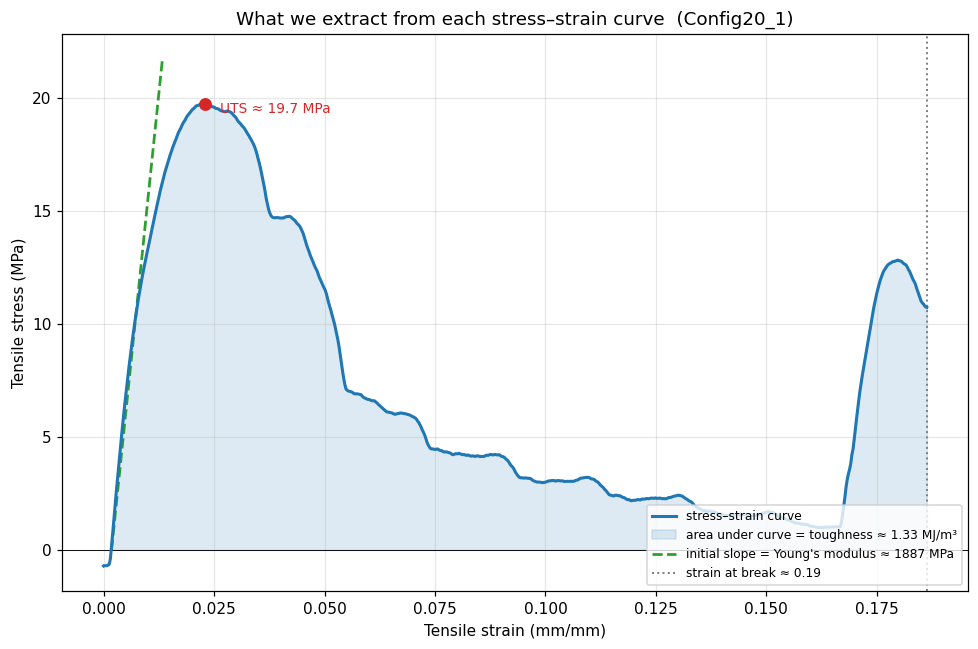

In [6]:
plots.curve_anatomy(curves, tensile_summary, pick="Config20_1",
                    save=p.figures / "tensile_curve_anatomy.png")

### 1.6 Stress–strain curves (one per configuration)

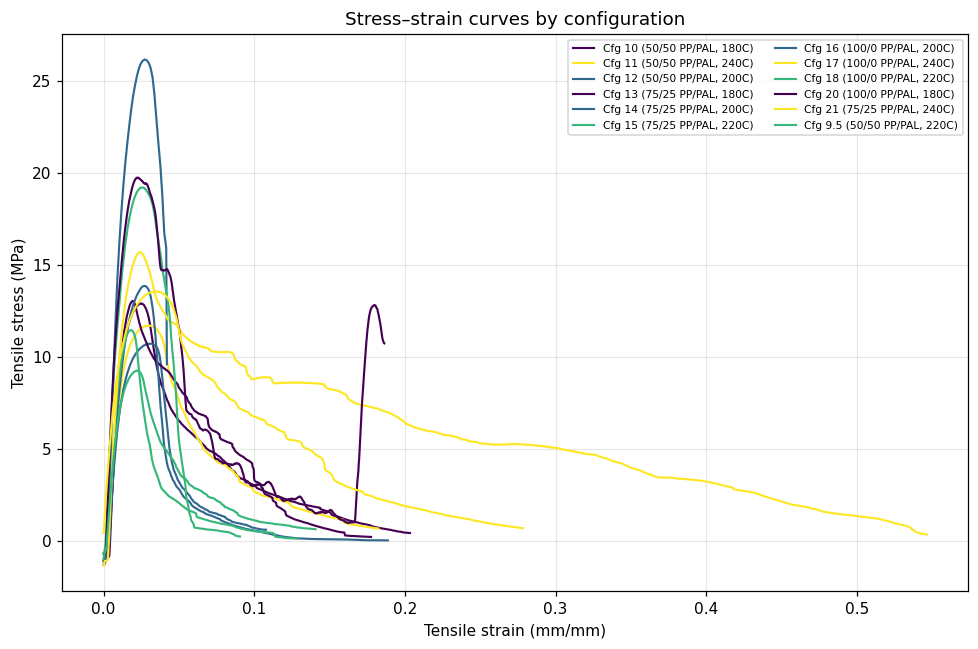

In [7]:
plots.stress_strain(curves, tensile_summary, config_meta,
                    save=p.figures / "tensile_stress_strain.png")

### 1.7 Mechanical properties vs. extrusion temperature

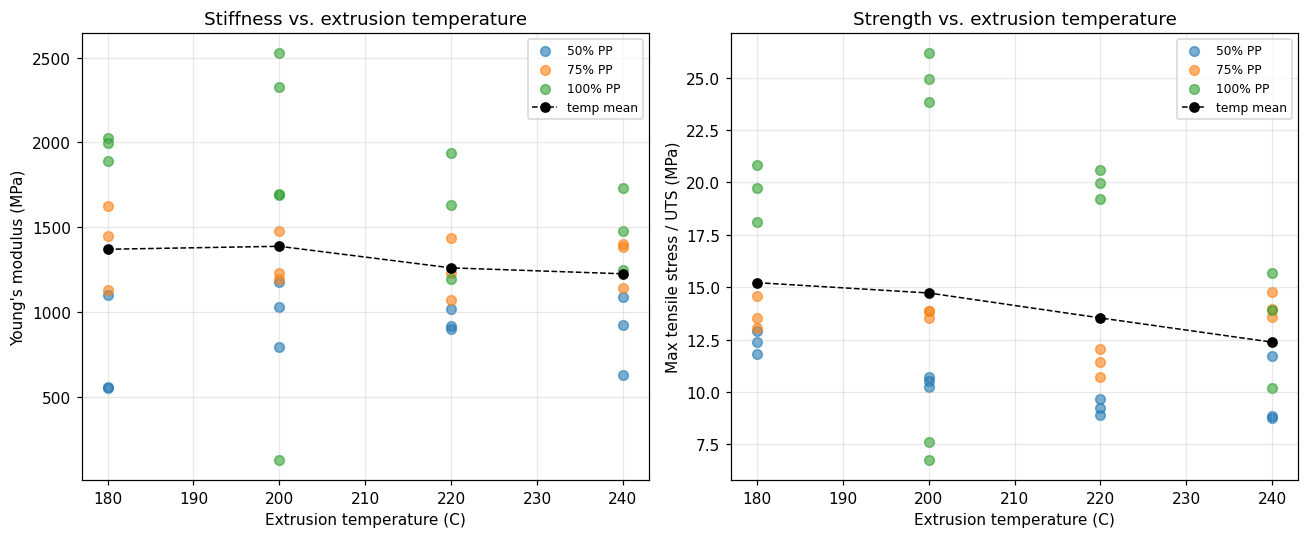

In [8]:
plots.props_vs_temp(tensile_summary, save=p.figures / "tensile_properties_vs_temp.png")

### 1.8 Design space — composition × temperature
Full 3×4 grid (PAL% ∈ {0,25,50} × temp ∈ {180,200,220,240 °C}). Heatmaps for strength,
stiffness, and toughness, plus a 3-D strength surface.

In [9]:
design = tensile.design_space(tensile_summary)
design.to_csv(p.tensile / "design_space_summary.csv", index=False)
g_stress = tensile.grid(design, "max_stress_mean")
g_mod    = tensile.grid(design, "modulus_mean")
g_tough  = tensile.grid(design, "toughness_mean")
g_stress.round(1)

extr_temp_C,180.0,200.0,220.0,240.0
pal_pct,,,,
50.0,12.4,10.5,9.3,9.8
25.0,13.7,13.7,11.4,14.1
0.0,19.6,17.9,19.9,13.3


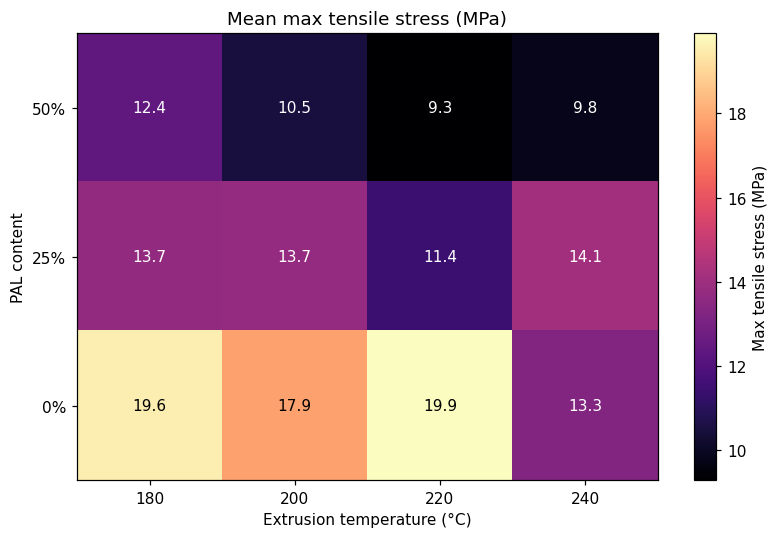

In [10]:
plots.heatmap(g_stress, "Mean max tensile stress (MPa)", "Max tensile stress (MPa)",
              cmap="magma", fmt=".1f", save=p.figures / "tensile_maxstress_heatmap.png")

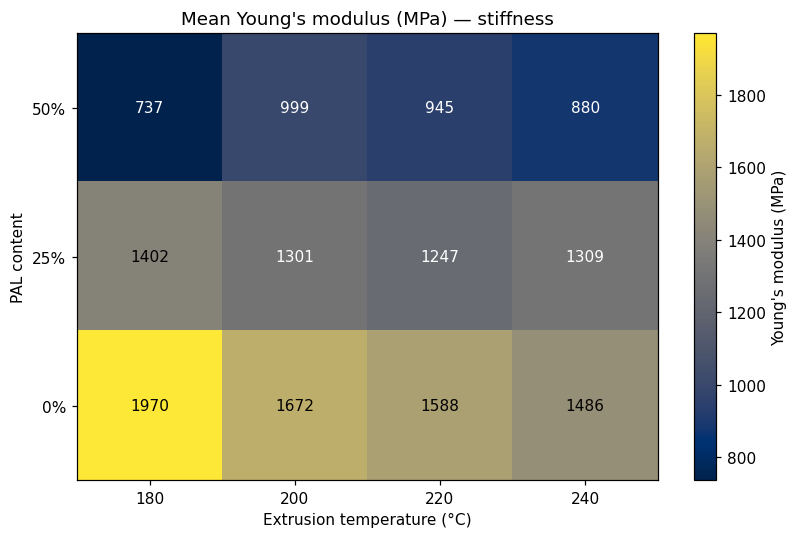

In [11]:
plots.heatmap(g_mod, "Mean Young's modulus (MPa) — stiffness", "Young's modulus (MPa)",
              cmap="cividis", fmt=".0f", save=p.figures / "tensile_modulus_heatmap.png")

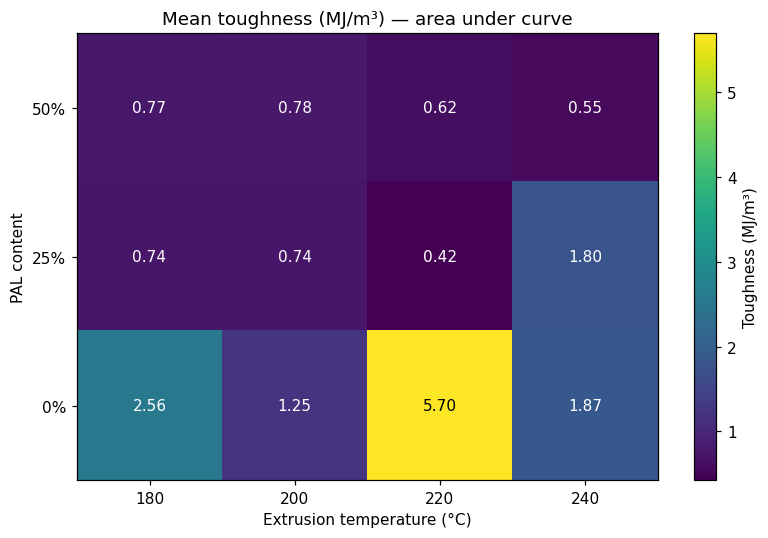

In [12]:
plots.heatmap(g_tough, "Mean toughness (MJ/m³) — area under curve", "Toughness (MJ/m³)",
              cmap="viridis", fmt=".2f", save=p.figures / "tensile_toughness_heatmap.png")

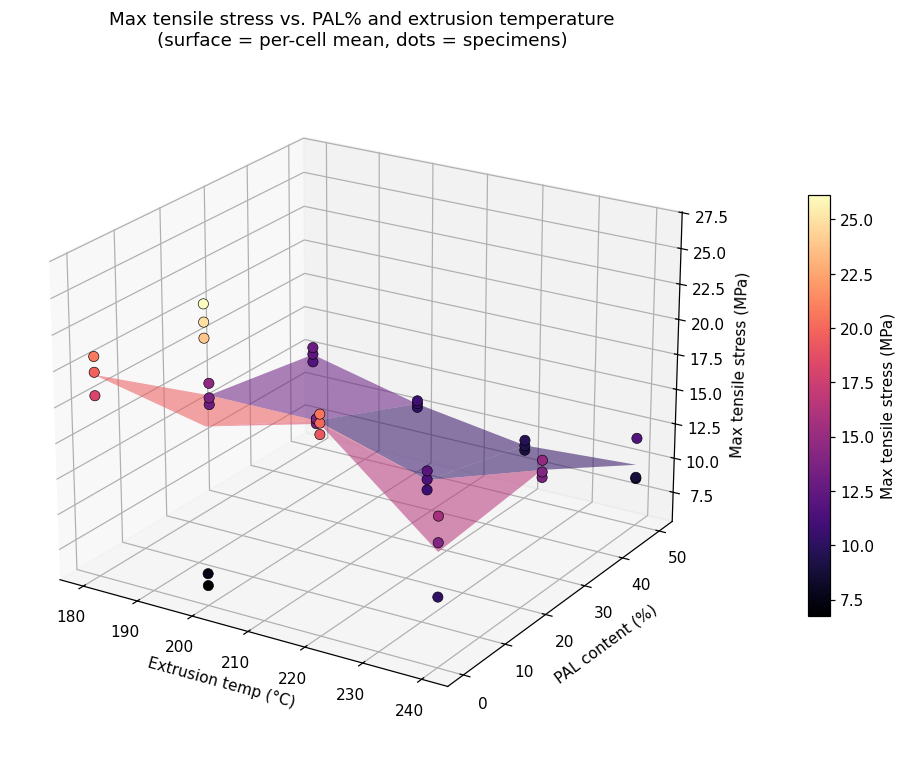

In [13]:
plots.maxstress_3d(tensile_summary, g_stress, save=p.figures / "tensile_maxstress_3d.png")

### 1.9 UTS ↔ toughness correlation (multi-objective check)
Objectives should ideally be ~uncorrelated. Pearson *r* (linear) + Spearman *ρ* (monotonic).

UTS vs toughness — Pearson r = 0.401 (p=0.0125), Spearman ρ = 0.508


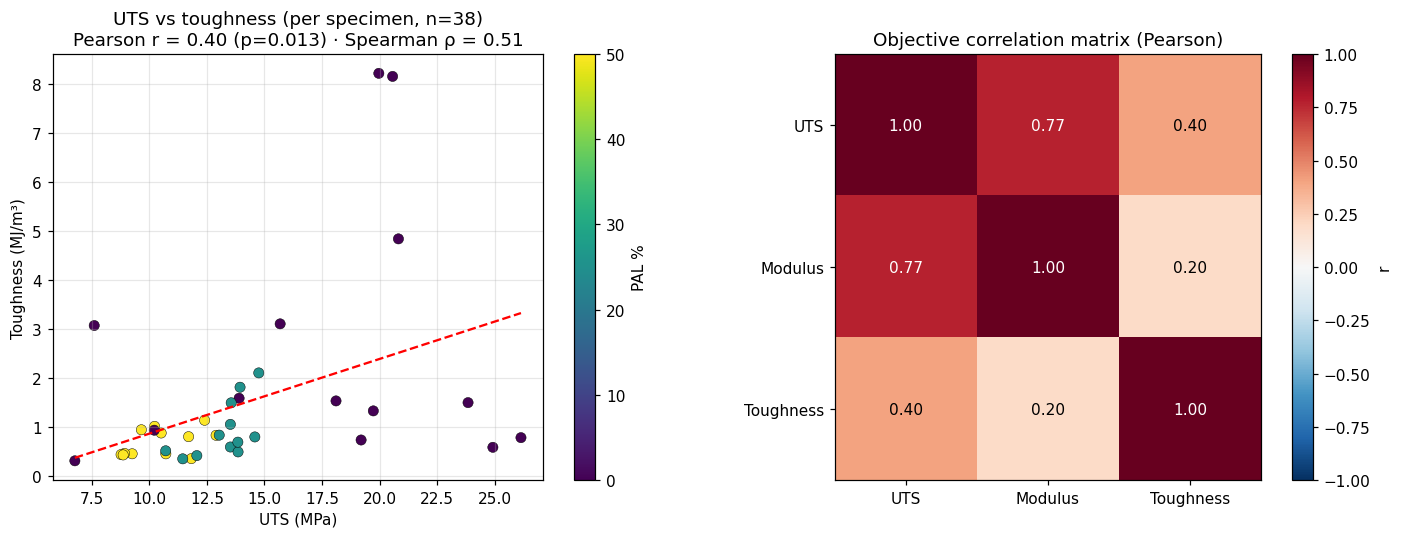

In [14]:
corr = tensile.objective_correlations(tensile_summary)
corr.to_csv(p.tensile / "objective_correlations.csv")
st = tensile.uts_toughness_stats(tensile_summary)
print(f"UTS vs toughness — Pearson r = {st['pearson_r']:.3f} (p={st['pearson_p']:.4f}), "
      f"Spearman ρ = {st['spearman_rho']:.3f}")
plots.correlation(tensile_summary, corr, st,
                  save=p.figures / "tensile_uts_toughness_correlation.png")

---
## Part 2 — Rheology study

### 2.1 Parse flow curves → summary
Headerless rheometer export; columns identified via viscosity = shear-stress / shear-rate.
Power-law fit `η = K·γ̇^(n-1)` over the ≤ 10 s⁻¹ region.

In [15]:
rheo_curves, rheology_summary = rheology.load_rheology(VISCOSITY_XLSX, p.rheology_curves)
rheology_summary.to_csv(p.rheology / "rheology_summary.csv", index=False)
rheology_summary.round(3)

,sample,recycle_level,file,n_points,shear_rate_min,shear_rate_max,viscosity_at_lowest_shear_Pa_s,powerlaw_K,powerlaw_n
0,1x-using shredded 3D print,1x,1x_using_shredded_3D_print.csv,31,0.1,100.00,2063.0,1515.527,0.840
1,1x_test2,1x,1x_test2.csv,31,0.1,100.00,3114.0,2422.125,0.834
2,1x_test3,1x,1x_test3.csv,31,0.1,100.00,2311.0,1905.440,0.871
3,1x_test4,1x,1x_test4.csv,31,0.1,100.00,3319.0,2503.392,0.857
4,1x_test5,1x,1x_test5.csv,31,0.1,100.00,3748.0,2843.685,0.837
5,5x-recycled,5x,5x_recycled.csv,31,0.1,100.00,2813.0,1980.119,0.786
6,5x_test 2,5x,5x_test_2.csv,30,0.1,79.44,7008.0,4007.727,0.638
7,5x_test3,5x,5x_test3.csv,31,0.1,100.00,5883.0,3414.878,0.608
8,5x_test4,5x,5x_test4.csv,31,0.1,100.00,5241.0,3363.800,0.699


### 2.2 Flow curves (log–log)

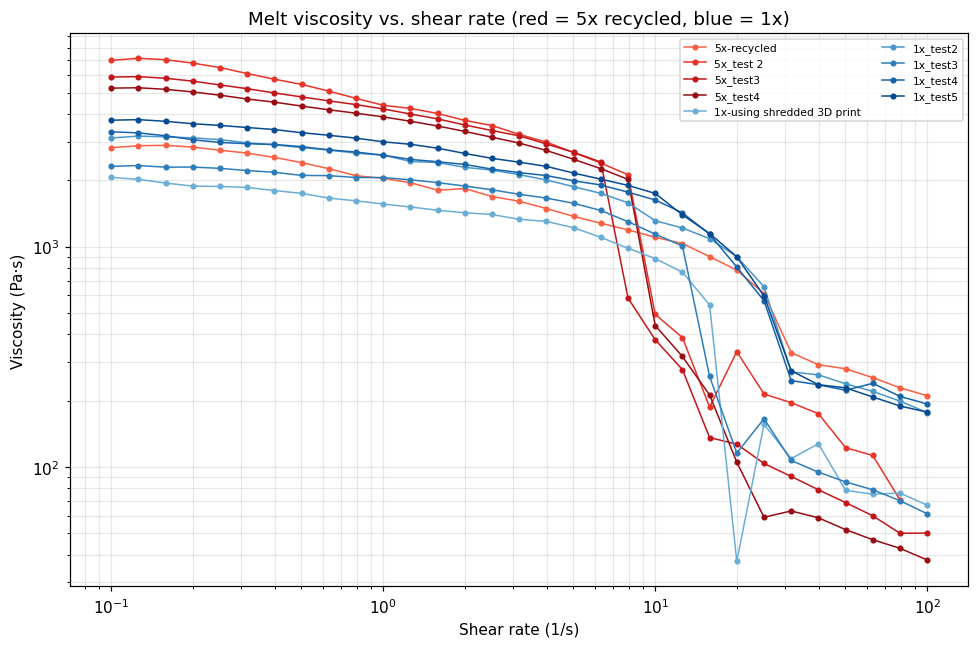

In [16]:
plots.flow_curves(rheo_curves, save=p.figures / "rheology_flow_curves.png")

### 2.3 Recycle-level comparison
Geometric mean (correct for log-scaled viscosity) with a min–max spread band.

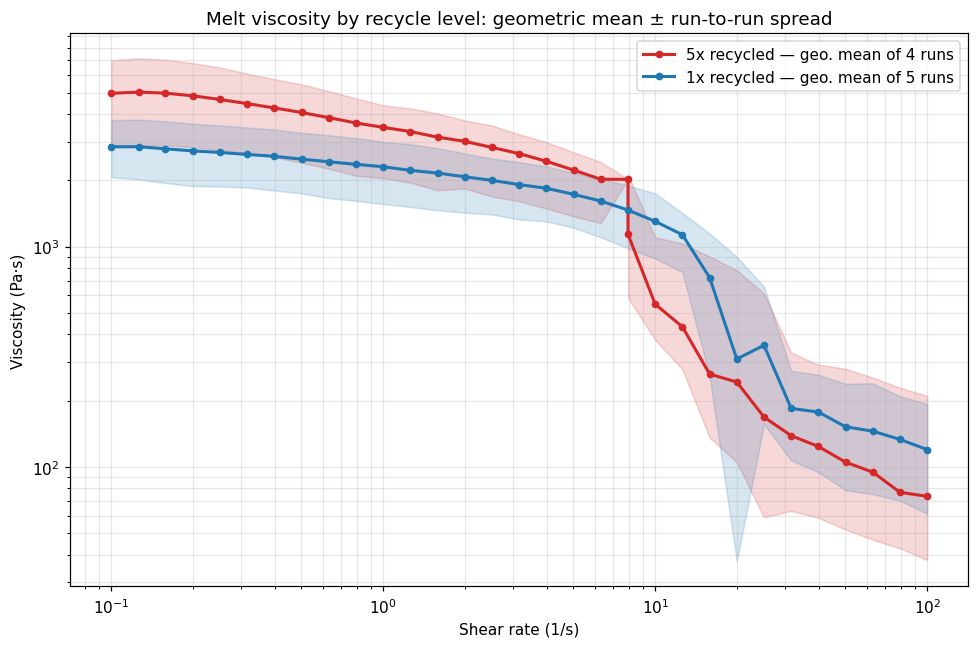

In [17]:
plots.recycle_comparison(rheo_curves, save=p.figures / "rheology_recycle_comparison.png")

### 2.4 Extrusion-relevant window (0.1–10 s⁻¹, proposed by Anupam)
Low-shear region is the useful one; the high-shear drop is a plate-slip artifact (to redo).

In [18]:
win = rheology.window_summary(rheo_curves)
win.to_csv(p.rheology / "extrusion_window_summary.csv", index=False)
win.round(1)

,recycle_level,n_runs,geo_mean_viscosity_Pa_s,min_Pa_s,max_Pa_s
0,1x,5,2184.9,882.7,3770.0
1,5x,4,3089.9,377.9,7157.0


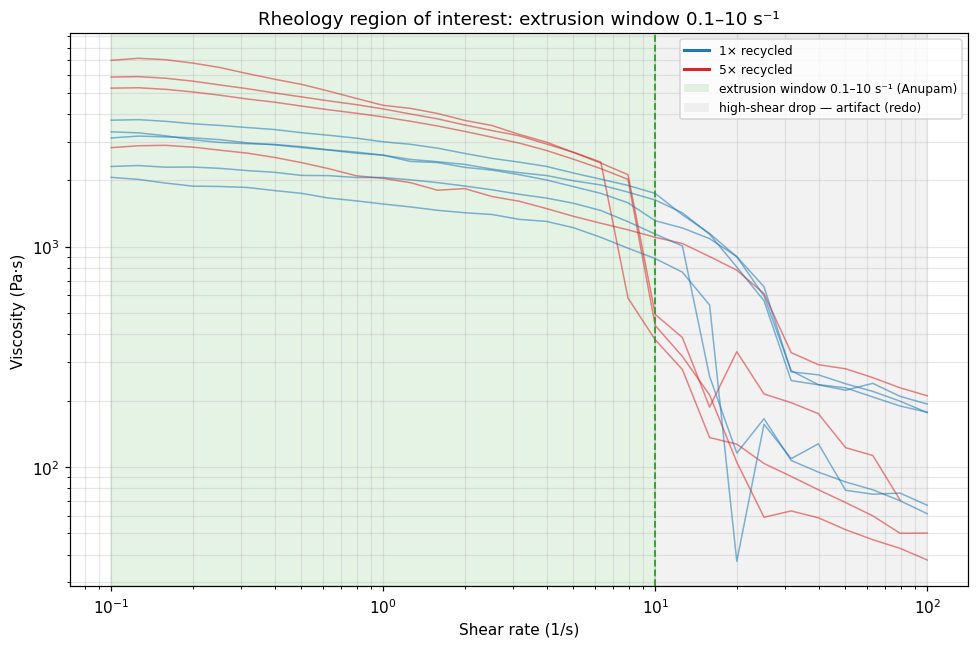

In [19]:
plots.extrusion_window(rheo_curves, save=p.figures / "rheology_extrusion_window.png")

---
## Part 3 — Design of experiments (optimized LHS)

Space-filling design over the **formulation** factors: polymer system (categorical, ≥3 for LVGP)
× PAL % (continuous 10–50) × extrusion temperature (continuous 180–240 °C). Polymer levels are
balanced via LHS strata; continuous factors sampled continuously.

**Recycle level is *not* a design factor** — recycling is a within-sample *degradation series*
(the same material recycled 0 → 1 → 5 → 10× and measured at each stage, esp. in the rheology
test). So we generate the formulations, then expand each by the recycle series into the
measurement plan. `N_FORMULATIONS` / `RECYCLES` live in `utils/config.py`. Saved to `doe/`.

In [20]:
design, quality = doe.optimized_lhs()
design.to_csv(p.doe / "doe_formulations.csv", index=False)
design.to_excel(p.doe / "doe_formulations.xlsx", index=False, engine="openpyxl")
print("quality:", quality)
print("polymer balance:", design.polymer_system.value_counts().to_dict())
design

quality: {'n_formulations': 12, 'discrepancy': 0.007710339228365726, 'max_factor_corr': 0.07403183295997459}
polymer balance: {'HDPE+PAL': 4, 'PP+PAL': 4, 'TPU+PAL': 4}


,formulation,polymer_system,PAL_pct,extrusion_temp_C
0,1,HDPE+PAL,49,220
1,2,HDPE+PAL,23,235
2,3,PP+PAL,15,225
3,4,PP+PAL,28,180
4,5,TPU+PAL,37,230
5,6,PP+PAL,41,205
6,7,TPU+PAL,11,200
7,8,TPU+PAL,46,185
8,9,HDPE+PAL,35,200
9,10,HDPE+PAL,19,195


In [21]:
# Expand each formulation across the recycle degradation series -> measurement plan.
plan = doe.expand_recycle(design)
plan.to_csv(p.doe / "doe_measurement_plan.csv", index=False)
plan.to_excel(p.doe / "doe_measurement_plan.xlsx", index=False, engine="openpyxl")
print(f"{len(design)} formulations × {plan['recycle_level'].nunique()} recycle levels "
      f"= {len(plan)} measurements (each formulation swept 0/1/5/10×)")
plan.head(12)

12 formulations × 4 recycle levels = 48 measurements (each formulation swept 0/1/5/10×)


,run,formulation,polymer_system,PAL_pct,extrusion_temp_C,recycle_level
0,1,1,HDPE+PAL,49,220,0
1,2,1,HDPE+PAL,49,220,1
2,3,1,HDPE+PAL,49,220,5
3,4,1,HDPE+PAL,49,220,10
4,5,2,HDPE+PAL,23,235,0
5,6,2,HDPE+PAL,23,235,1
6,7,2,HDPE+PAL,23,235,5
7,8,2,HDPE+PAL,23,235,10
8,9,3,PP+PAL,15,225,0
9,10,3,PP+PAL,15,225,1


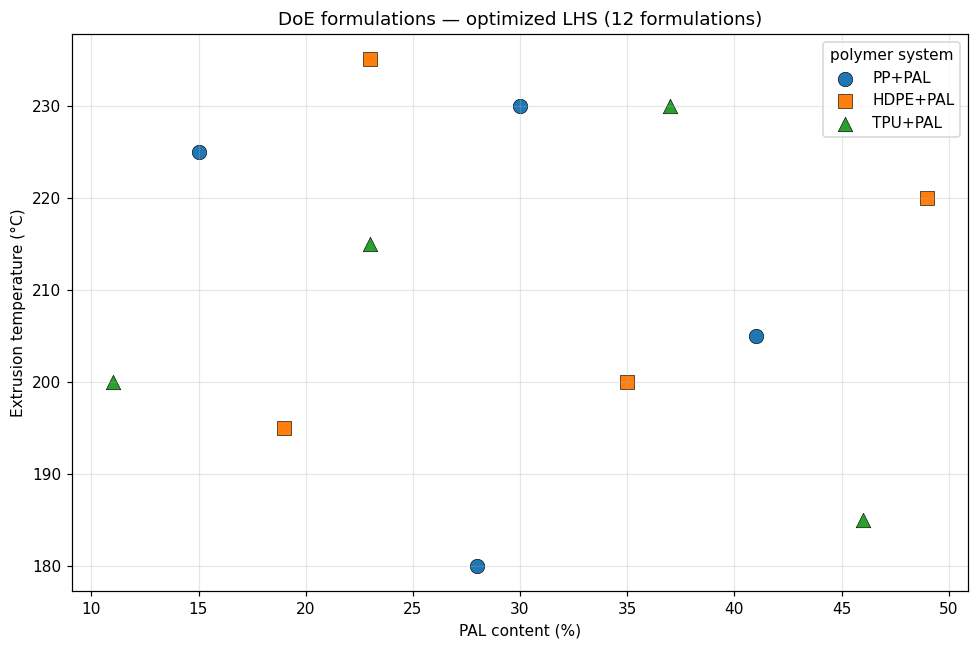

In [22]:
plots.doe_scatter(design, save=p.figures / "doe_formulations.png")

### 3.1 Design diagnostics — how good is the sampling?

A space-filling design is judged on **coverage uniformity** and **factor independence**, not
accuracy. We score it in the unit cube $\mathbf{u}_i \in [0,1)^d$ ($d=3$ factors, $n$ points).

**Centered $L_2$ discrepancy** — deviation from a perfectly uniform spread over the cube
(lower = better). This is exactly the criterion `optimization="random-cd"` minimizes:

$$
CD^2 = \left(\tfrac{13}{12}\right)^{d}
- \frac{2}{n}\sum_{i=1}^{n}\prod_{k=1}^{d}\!\left(1+\tfrac12\,|u_{ik}-\tfrac12|-\tfrac12\,|u_{ik}-\tfrac12|^{2}\right)
+ \frac{1}{n^{2}}\sum_{i=1}^{n}\sum_{j=1}^{n}\prod_{k=1}^{d}\!\left(1+\tfrac12\,|u_{ik}-\tfrac12|+\tfrac12\,|u_{jk}-\tfrac12|-\tfrac12\,|u_{ik}-u_{jk}|\right)
$$

**Maximin distance** — how close the two nearest points get; maximizing it prevents clustering
(higher = better):

$$
\phi_{\min} = \min_{i\neq j}\ \lVert \mathbf{u}_i-\mathbf{u}_j\rVert_2
$$

**Max absolute factor correlation** — worst confounding between factors; near $0$ keeps their
effects separable in the model (lower = better):

$$
\rho_{\max} = \max_{k\neq l}\ \bigl|\operatorname{corr}(\mathbf{x}_{\cdot k},\,\mathbf{x}_{\cdot l})\bigr|
$$

**Fill distance (coverage radius)** — the largest hole: the farthest any point in the space sits
from its nearest sample (lower = better). It is the *minimax* objective; the supremum is
Monte-Carlo estimated with probe points:

$$
h = \sup_{\mathbf{x}\in[0,1]^{d}}\ \min_{i}\ \lVert \mathbf{x}-\mathbf{u}_i\rVert_2
$$

**Level balance** (categorical polymer): each of the $L$ levels should appear $n/L$ times.

In [23]:
# Rebuild the unit-cube design (same seed as utils.doe) and score it.
from scipy.stats import qmc
U = qmc.LatinHypercube(d=3, optimization="random-cd",
                       seed=config.DOE.seed).random(config.DOE.n_formulations)
m = doe.design_metrics(U)
print(f"centered discrepancy : {m['centered_discrepancy']:.5f}   (lower better)")
print(f"maximin distance     : {m['maximin']:.4f}   (higher better)")
print(f"max |factor corr|    : {m['max_abs_corr']:.3f}    (lower better)")
print(f"fill distance        : {m['fill_distance']:.4f}   (lower better)")
print(f"polymer level balance: {design.polymer_system.value_counts().to_dict()}")

centered discrepancy : 0.00771   (lower better)
maximin distance     : 0.3571   (higher better)
max |factor corr|    : 0.074    (lower better)
fill distance        : 0.5539   (lower better)
polymer level balance: {'HDPE+PAL': 4, 'PP+PAL': 4, 'TPU+PAL': 4}


Benchmarked against plain (unoptimized) LHS and random sampling, averaged over many seeds —
the optimized LHS should win on every metric.

In [24]:
bench = doe.benchmark_designs()
bench.round(4)

,centered_discrepancy,maximin,max_abs_corr,fill_distance
optimized LHS,0.0077,0.3571,0.0740,0.5539
plain LHS (avg),0.0126,0.1987,0.3957,0.6414
random (avg),0.0579,0.1394,0.4341,0.7171


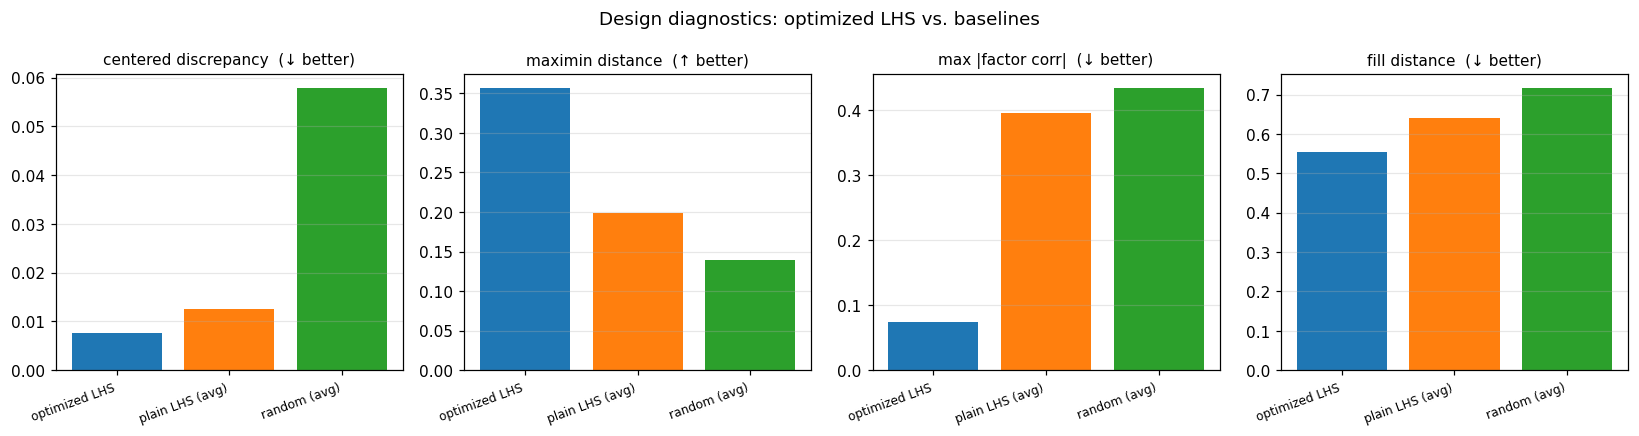

In [25]:
plots.design_benchmark(bench, save=p.figures / "doe_diagnostics.png")

---
## Outputs

In [26]:
for f in sorted(p.proc.rglob("*")):
    if f.is_file():
        print(f.relative_to(p.root))
for f in sorted(p.doe.glob("*")):
    print(f.relative_to(p.root))

processed_data/figures/doe_diagnostics.png
processed_data/figures/doe_formulations.png
processed_data/figures/rheology_extrusion_window.png
processed_data/figures/rheology_flow_curves.png
processed_data/figures/rheology_recycle_comparison.png
processed_data/figures/tensile_curve_anatomy.png
processed_data/figures/tensile_maxstress_3d.png
processed_data/figures/tensile_maxstress_heatmap.png
processed_data/figures/tensile_modulus_heatmap.png
processed_data/figures/tensile_properties_vs_temp.png
processed_data/figures/tensile_stress_strain.png
processed_data/figures/tensile_toughness_heatmap.png
processed_data/figures/tensile_uts_toughness_correlation.png
processed_data/rheology/curves/1x_test2.csv
processed_data/rheology/curves/1x_test3.csv
processed_data/rheology/curves/1x_test4.csv
processed_data/rheology/curves/1x_test5.csv
processed_data/rheology/curves/1x_using_shredded_3D_print.csv
processed_data/rheology/curves/5x_recycled.csv
processed_data/rheology/curves/5x_test3.csv
processed_